In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_train, load_test, remove_outliers, split_xy
from src.cleaning import clean

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


In [2]:
train_df = remove_outliers(load_train())
print(len(load_train()), "->", len(train_df), "rows after removing outliers") # 1460 -> 1458 on the real data

X, y = split_xy(train_df)
cleaned = clean(X)

before = X.isna().sum()
after = cleaned.isna().sum()
gaps = pd.DataFrame({"before": before, "after": after.reindex(before.index)})
gaps[gaps["before"] > 0].sort_values("before", ascending=False).head(15)

1460 -> 1458 rows after removing outliers


,before,after
PoolQC,1452,0.0
MiscFeature,1404,0.0
Alley,1367,0.0
Fence,1177,0.0
MasVnrType,872,0.0
FireplaceQu,690,0.0
LotFrontage,259,259.0
GarageType,81,0.0
GarageYrBlt,81,NaN
GarageFinish,81,0.0


In [3]:
from src.features import add_features

fe = add_features(cleaned)
new_cols = [c for c in fe.columns if c not in cleaned.columns]
print(new_cols)

check = fe[new_cols + ["OverallQual", "GrLivArea"]].assign(LogPrice=y.values)
check.corr()["LogPrice"].sort_values(ascending=False).round(2)


['TotalSF', 'TotalBath', 'TotalPorchSF', 'HouseAge', 'RemodAge', 'IsRemodeled', 'IsNew', 'HasPool', 'HasGarage', 'HasBasement', 'HasFireplace', 'Has2ndFloor', 'QualSF']


LogPrice        1.00
QualSF          0.88
TotalSF         0.83
OverallQual     0.82
GrLivArea       0.73
TotalBath       0.68
HasFireplace    0.51
TotalPorchSF    0.40
HasGarage       0.32
IsNew           0.22
HasBasement     0.20
Has2ndFloor     0.15
HasPool         0.08
IsRemodeled    -0.07
RemodAge       -0.57
HouseAge       -0.59
Name: LogPrice, dtype: float64

In [4]:
from sklearn.linear_model import Ridge
from src.pipeline import build_pipeline

pipe = build_pipeline(Ridge(alpha=10)).fit(X, y)
Z = pipe[:-1].transform(X) # everything except the final model
print(Z.shape, "NaN left:", int(np.isnan(Z).sum()))

names = pipe.named_steps["prep"].get_feature_names_out()
print(len(names), "columns, e.g.", list(names[:4]), "...", list(names[-2:]))

skewed = pipe.named_steps["prep"].named_transformers_["num"].named_steps["skew"].skewed_
print(len(skewed), "numeric columns got a log transform")

(1458, 224) NaN left: 0
224 columns, e.g. ['num__LotFrontage', 'num__LotArea', 'num__LotShape', 'num__LandSlope'] ... ['cat__SaleCondition_Partial', 'cat__SaleCondition_infrequent_sklearn']
36 numeric columns got a log transform


In [5]:
from sklearn.dummy import DummyRegressor
from src.cv import cv_rmse, CV, rmse

results = {}
def evaluate(name, model):
 mean, std = cv_rmse(model, X, y)
 results[name] = (mean, std)
 print(f"{name:<24} RMSE {mean:.4f} +/- {std:.4f}")
 
evaluate("baseline (always the mean)", build_pipeline(DummyRegressor(strategy="mean")))
evaluate("ridge alpha=10", build_pipeline(Ridge(alpha=10)))

baseline (always the mean) RMSE 0.3993 +/- 0.0168
ridge alpha=10           RMSE 0.1136 +/- 0.0077


In [6]:
test = load_test()
X_test = test.drop(columns="Id")

ridge = build_pipeline(Ridge(alpha=10)).fit(X, y) # fit on ALL training rows
quick = pd.DataFrame({"Id": test["Id"], "SalePrice": np.expm1(ridge.predict(X_test))}) # back to dollars
quick.to_csv("../submissions/submission_ridge.csv", index=False)
quick.head()

,Id,SalePrice
0,1461,118020.144261
1,1462,152590.431147
2,1463,178036.167993
3,1464,199720.685737
4,1465,200165.407042


In [7]:
from sklearn.linear_model import LinearRegression
evaluate("linear regression (no penalty)", build_pipeline(LinearRegression()))
for a in [1, 3, 10, 30, 100]:
 evaluate(f"ridge alpha={a}", build_pipeline(Ridge(alpha=a)))

linear regression (no penalty) RMSE 0.1872 +/- 0.1256
ridge alpha=1            RMSE 0.1157 +/- 0.0078
ridge alpha=3            RMSE 0.1141 +/- 0.0077
ridge alpha=10           RMSE 0.1136 +/- 0.0077
ridge alpha=30           RMSE 0.1143 +/- 0.0079
ridge alpha=100          RMSE 0.1171 +/- 0.0084


In [8]:
plain = build_pipeline(LinearRegression()).fit(X, y)
ridge10 = build_pipeline(Ridge(alpha=10)).fit(X, y)
print("largest |weight|, no penalty:", round(float(np.abs(plain.named_steps["model"].coef_).max()), 3))
print("largest |weight|, ridge :", round(float(np.abs(ridge10.named_steps["model"].coef_).max()), 3))

largest |weight|, no penalty: 5.716
largest |weight|, ridge : 0.137


In [9]:
from src.pipeline import make_models
models = make_models()
for name in ["ridge", "lasso", "elasticnet"]:
 evaluate(name, models[name])


ridge                    RMSE 0.1132 +/- 0.0077
lasso                    RMSE 0.1115 +/- 0.0067
elasticnet               RMSE 0.1115 +/- 0.0067


In [10]:
lasso = models["lasso"].fit(X, y)
coefs = pd.Series(lasso.named_steps["model"].coef_,
 index=lasso.named_steps["prep"].get_feature_names_out())
print("chosen alpha:", round(float(lasso.named_steps["model"].alpha_), 5))
print((coefs != 0).sum(), "of", len(coefs), "features kept")

pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)]).round(3)

chosen alpha: 0.00033
118 of 224 features kept


cat__MSZoning_C (all)                -0.313
num__HouseAge                        -0.074
num__KitchenAbvGr                    -0.068
num__HasBasement                     -0.056
cat__SaleCondition_Abnorml           -0.043
cat__Condition1_RRAe                 -0.043
cat__GarageType_infrequent_sklearn   -0.042
cat__Neighborhood_Edwards            -0.030
cat__Exterior1st_BrkFace              0.061
cat__Neighborhood_NridgHt             0.061
cat__Neighborhood_NoRidge             0.064
cat__Neighborhood_StoneBr             0.102
num__OverallQual                      0.104
cat__Neighborhood_Crawfor             0.107
num__GrLivArea                        0.135
num__Functional                       0.198
dtype: float64

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor

evaluate("random forest", models["forest"])
evaluate("gradient boosting (huber)", models["gbr"])
evaluate("hist gradient boosting",
 build_pipeline(HistGradientBoostingRegressor(
     learning_rate=0.05, max_iter=400, max_leaf_nodes=15, min_samples_leaf=10,
     l2_regularization=1.0, random_state=RANDOM_STATE), scale=False))


random forest            RMSE 0.1292 +/- 0.0079
gradient boosting (huber) RMSE 0.1111 +/- 0.0073
hist gradient boosting   RMSE 0.1217 +/- 0.0103


In [12]:
table = pd.DataFrame(results, index=["cv_rmse", "std"]).T.sort_values("cv_rmse")
table["typical_error_%"] = ((np.exp(table["cv_rmse"]) - 1) * 100).round(1)
table.round(4)

,cv_rmse,std,typical_error_%
gradient boosting (huber),0.1111,0.0073,11.8
elasticnet,0.1115,0.0067,11.8
lasso,0.1115,0.0067,11.8
ridge,0.1132,0.0077,12.0
ridge alpha=10,0.1136,0.0077,12.0
ridge alpha=3,0.1141,0.0077,12.1
ridge alpha=30,0.1143,0.0079,12.1
ridge alpha=1,0.1157,0.0078,12.3
ridge alpha=100,0.1171,0.0084,12.4
hist gradient boosting,0.1217,0.0103,12.9


In [13]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

xgb = build_pipeline(XGBRegressor(
 n_estimators=1500, learning_rate=0.02, max_depth=3, subsample=0.7, colsample_bytree=0.5,
 reg_alpha=0.005, reg_lambda=1.0, tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1), scale=False)

lgbm = build_pipeline(LGBMRegressor(
 n_estimators=1500, learning_rate=0.02, num_leaves=8, subsample=0.7, subsample_freq=1,
 colsample_bytree=0.5, reg_lambda=1.0, random_state=RANDOM_STATE, verbose=-1), scale=False)

evaluate("xgboost", xgb)
evaluate("lightgbm", lgbm)

xgboost                  RMSE 0.1116 +/- 0.0067
lightgbm                 RMSE 0.1178 +/- 0.0087


In [14]:
from scipy.stats import loguniform, randint, uniform
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

search = RandomizedSearchCV(
 build_pipeline(GradientBoostingRegressor(n_estimators=600, loss="huber", max_features="sqrt",
                                          random_state=RANDOM_STATE), scale=False),
 param_distributions={
 "model__learning_rate": loguniform(0.01, 0.1),
 "model__max_depth": randint(2, 6),
 "model__min_samples_leaf": randint(5, 30),
 "model__subsample": uniform(0.6, 0.4), # 0.6 to 1.0
 },
 n_iter=12, cv=CV, scoring="neg_root_mean_squared_error",
 random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X, y)
print("best CV RMSE:", round(-search.best_score_, 4))
print(search.best_params_)


Fitting 5 folds for each of 12 candidates, totalling 60 fits
best CV RMSE: 0.1132
{'model__learning_rate': np.float64(0.04475983459259064), 'model__max_depth': 2, 'model__min_samples_leaf': 6, 'model__subsample': np.float64(0.8887995089067299)}


In [15]:
res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cols = ["mean_test_score", "param_model__learning_rate", "param_model__max_depth",
 "param_model__min_samples_leaf", "param_model__subsample"]
res[cols].head(5).round(4)

,mean_test_score,param_model__learning_rate,param_model__max_depth,param_model__min_samples_leaf,param_model__subsample
3,-0.1132,0.0448,2,6,0.8888
6,-0.1142,0.0335,4,14,0.6187
1,-0.1148,0.0397,4,23,0.6400
10,-0.1154,0.0889,5,18,0.9234
4,-0.1161,0.0868,3,25,0.8470


In [16]:
from sklearn.model_selection import RepeatedKFold, cross_val_score

rcv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
for name, m in [("gbr untuned", models["gbr"]), ("gbr tuned", search.best_estimator_)]:
 s = -cross_val_score(m, X, y, cv=rcv, scoring="neg_root_mean_squared_error", n_jobs=-1)
 print(f"{name:<12} {s.mean():.4f} +/- {s.std():.4f} (15 fits)")
 
models["gbr_tuned"] = search.best_estimator_ # add it to the set we will blend in Step 12

gbr untuned  0.1108 +/- 0.0058 (15 fits)
gbr tuned    0.1130 +/- 0.0050 (15 fits)


In [17]:
from src.cv import oof_predictions, blend_weights

oof = oof_predictions(models, X, y) # one honest prediction per row per model
print(oof.corr().round(3)) # how similar are the models' predictions?
for name in oof:
 print(f"{name:<12} OOF RMSE {rmse(y, oof[name]):.4f}")
 
weights = blend_weights(oof, y)
print("weights:", weights.round(3).to_dict())
print("blend RMSE :", round(rmse(y, oof.values @ weights.values), 4))
print("simple average :", round(rmse(y, oof.mean(axis=1)), 4))

            ridge  lasso  elasticnet    gbr  forest  gbr_tuned
ridge       1.000  0.998       0.999  0.987   0.976      0.988
lasso       0.998  1.000       1.000  0.988   0.975      0.988
elasticnet  0.999  1.000       1.000  0.988   0.976      0.988
gbr         0.987  0.988       0.988  1.000   0.982      0.996
forest      0.976  0.975       0.976  0.982   1.000      0.984
gbr_tuned   0.988  0.988       0.988  0.996   0.984      1.000
ridge        OOF RMSE 0.1135
lasso        OOF RMSE 0.1117
elasticnet   OOF RMSE 0.1117
gbr          OOF RMSE 0.1114
forest       OOF RMSE 0.1295
gbr_tuned    OOF RMSE 0.1134
weights: {'ridge': 0.0, 'lasso': 0.448, 'elasticnet': 0.034, 'gbr': 0.482, 'forest': 0.006, 'gbr_tuned': 0.03}
blend RMSE : 0.1073
simple average : 0.1084


In [18]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV

stack = StackingRegressor(
 estimators=[(n, models[n]) for n in ["lasso", "elasticnet", "gbr"]],
 final_estimator=RidgeCV(alphas=np.logspace(-3, 1, 20)),
 cv=5, n_jobs=-1,
)
evaluate("stacking", stack) # slow: every base model is refitted inside every fold

stacking                 RMSE 0.1071 +/- 0.0073


In [19]:
blend_dollars = np.expm1(oof.values @ weights.values)
resid = pd.DataFrame({"Id": train_df["Id"], "Neighborhood": train_df["Neighborhood"],
 "actual": train_df["SalePrice"], "predicted": blend_dollars})
resid["pct_error"] = (resid["predicted"] - resid["actual"]) / resid["actual"] * 100

worst = resid.reindex(resid["pct_error"].abs().sort_values(ascending=False).index).head(10)
worst.round(0)

,Id,Neighborhood,actual,predicted,pct_error
631,633,NWAmes,82500,177200.0,115.0
30,31,IDOTRR,40000,81357.0,103.0
462,463,Sawyer,62383,121588.0,95.0
1322,1325,Somerst,147000,280130.0,91.0
495,496,IDOTRR,34900,62464.0,79.0
967,969,OldTown,37900,67778.0,79.0
410,411,Edwards,60000,102882.0,71.0
587,589,ClearCr,143000,242286.0,69.0
1451,1454,Mitchel,84500,130739.0,55.0
1430,1433,OldTown,64500,98220.0,52.0


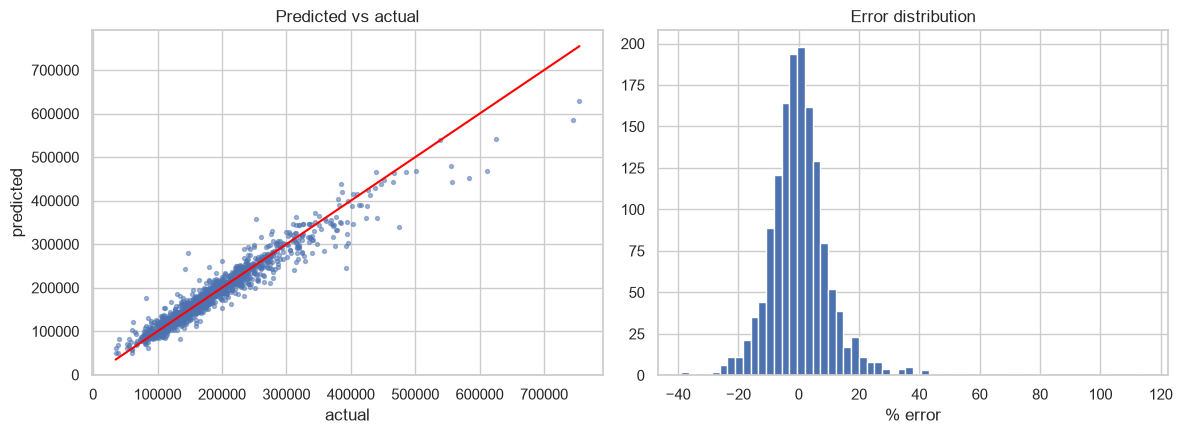

,mean,count
Neighborhood,,
IDOTRR,16.3,37
ClearCr,11.0,28
OldTown,10.1,113
SWISU,9.7,25
Edwards,9.5,98
Crawfor,9.2,51
BrkSide,8.7,58
StoneBr,8.3,25


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(resid["actual"], resid["predicted"], s=8, alpha=.5)
lim = [resid["actual"].min(), resid["actual"].max()]
axes[0].plot(lim, lim, color="red"); axes[0].set(xlabel="actual", ylabel="predicted", title="Predicted vs actual")
axes[1].hist(resid["pct_error"], bins=60); axes[1].set(xlabel="% error", title="Error distribution")
plt.tight_layout(); plt.show()

(resid.assign(abs_pct=resid["pct_error"].abs())
 .groupby("Neighborhood")["abs_pct"].agg(["mean", "count"])
 .sort_values("mean", ascending=False).head(8).round(1))


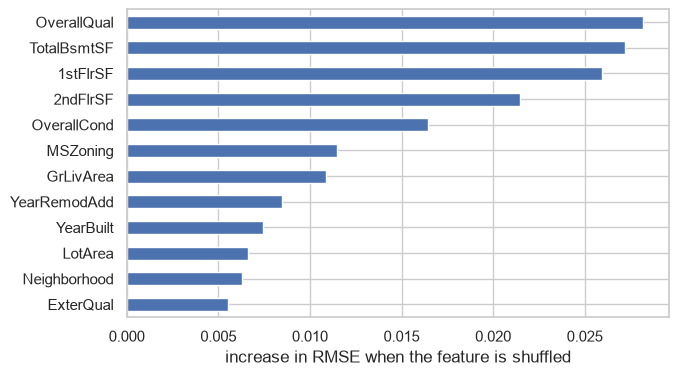

In [21]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
gbr = models["gbr"].fit(X_tr, y_tr) # fit on 80%, explain on the unseen 20%

r = permutation_importance(gbr, X_va, y_va, scoring="neg_root_mean_squared_error",
 n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_va.columns).sort_values(ascending=False)
imp.head(12).iloc[::-1].plot(kind="barh", figsize=(7, 4))
plt.xlabel("increase in RMSE when the feature is shuffled"); plt.show()

In [22]:
sub = pd.read_csv("../submissions/submission_blend.csv")
print(sub.shape) # (1459, 2)
print(sub["SalePrice"].describe().round(0))
print("train median:", train_df["SalePrice"].median(), " predicted median:", round(sub["SalePrice"].median()))

(1459, 2)
count      1459.0
mean     178654.0
std       77975.0
min       43409.0
25%      127373.0
50%      156897.0
75%      208704.0
max      845853.0
Name: SalePrice, dtype: float64
train median: 163000.0  predicted median: 156897
